
# Household Electricity Consumption Analysis and Forecasting

## 1. Project Introduction

### 1.1 Background

Understanding household electricity consumption is essential for effective energy management, demand forecasting, and power system planning. Electricity demand varies over time due to household activities, appliance usage, and daily or seasonal consumption patterns.

Analyzing historical electricity measurements can reveal these patterns and support the development of data-driven forecasting models.

### 1.2 Project Aim

The aim of this project is to analyze historical household electricity consumption data, identify temporal consumption patterns, and develop machine learning models for short-term electricity demand forecasting.

### 1.3 Research Objectives

The specific objectives are to:

1. Examine the structure, quality, and characteristics of household electricity consumption data.
2. Identify and address missing values, inconsistencies, and other data quality issues.
3. Investigate hourly, daily, weekly, and seasonal electricity consumption patterns.
4. Explore relationships between electrical measurements and household energy consumption.
5. Develop time-based, lagged, and rolling statistical features for forecasting.
6. Build and compare baseline and machine learning forecasting models.
7. Evaluate forecasting performance using appropriate error metrics.
8. Interpret the findings and discuss their implications for household energy management.

### 1.4 Dataset Overview

This project uses the **Individual Household Electric Power Consumption** dataset from the UCI Machine Learning Repository.

The dataset contains approximately 2.08 million measurements recorded at one-minute intervals between December 2006 and November 2010.

The measurements include active power, reactive power, voltage, current intensity, and three household energy sub-metering variables.

**Dataset source:** https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption

### 1.5 Project Methodology

The analysis follows eight major phases:

1. Project planning and dataset selection.
2. Project setup and version control.
3. Data loading and quality assessment.
4. Data cleaning and exploratory data analysis.
5. Time-series analysis and feature engineering.
6. Electricity demand forecasting.
7. Model evaluation and interpretation.
8. Final documentation and reproducibility review.

To avoid data leakage, forecasting models will be evaluated using chronological training and testing periods rather than random splitting.



### 1.6 Project Workflow Animation

The following animation illustrates the five main stages of the household electricity consumption analysis and forecasting workflow.

![Household Electricity Consumption and Forecasting Workflow](../figure/household_electricity_project_workflow.gif)

**Note:** The animation is a conceptual illustration of the project workflow. The electricity consumption patterns shown are illustrative rather than actual dataset results.



## 2. Python Environment and Library Imports

### 2.1 Import Required Libraries

This section imports the Python libraries required for data manipulation, numerical analysis, visualization, and file management.

Additional libraries for machine learning and forecasting will be introduced in later sections when needed.


In [1]:

# Import libraries for data analysis and visualization

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configure default visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("All required libraries imported successfully!")


All required libraries imported successfully!



### 2.2 Define Project Directories

To ensure reproducibility and maintain a well-organized project, the dataset and figure directories are defined using Python's `pathlib` library.

The notebook is stored in the `notebook/` directory, while the raw dataset is stored in `data/`. Generated visualizations will be saved in `figure/`.

Relative paths are used to avoid hardcoding computer-specific directory locations.


In [2]:

# Define the main project directory
PROJECT_DIR = Path.cwd().parent

# Define dataset and figure directories
DATA_DIR = PROJECT_DIR / "data"
FIGURE_DIR = PROJECT_DIR / "figure"

# Define the dataset file path
DATA_FILE = DATA_DIR / "household_power_consumption.txt"

# Check whether the dataset exists
print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Figure directory:", FIGURE_DIR)
print("Dataset exists:", DATA_FILE.is_file())


Project directory: C:\Users\USER\Desktop\ECE M2\M2 Sem 1\BIG DATA & ENERGY DATA ANALYSIS\Personal Projects\Household Electricity Consumption Analysis and Forecasting
Data directory: C:\Users\USER\Desktop\ECE M2\M2 Sem 1\BIG DATA & ENERGY DATA ANALYSIS\Personal Projects\Household Electricity Consumption Analysis and Forecasting\data
Figure directory: C:\Users\USER\Desktop\ECE M2\M2 Sem 1\BIG DATA & ENERGY DATA ANALYSIS\Personal Projects\Household Electricity Consumption Analysis and Forecasting\figure
Dataset exists: True



## 3. Data Loading and Initial Inspection

### 3.1 Load the Household Electricity Consumption Dataset

The dataset is loaded using Pandas. The original file uses semicolons (`;`) to separate variables and question marks (`?`) to represent missing measurements.

Missing-value indicators are converted into `NaN` values during import to facilitate subsequent data quality assessment and preprocessing.

The original date and time columns are preserved at this stage. Timestamp conversion and validation will be performed separately to allow systematic examination of the raw data.


In [3]:

# Load the household electricity consumption dataset

df = pd.read_csv(
    DATA_FILE,
    sep=";",
    na_values=["?"],
    low_memory=False
)

# Confirm successful loading
print("Dataset loaded successfully!")

# Display dataset dimensions
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

# Display the first five observations
display(df.head())


Dataset loaded successfully!
Number of rows: 2,075,259
Number of columns: 9


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0



### 3.2 Inspect Dataset Structure and Data Types

This section examines the structure of the loaded dataset, including its column names, data types, non-null observations, and memory usage.

The inspection helps identify variables that may require conversion or preprocessing before conducting time-series analysis.

In particular, the `Date` and `Time` variables must eventually be combined into a datetime representation suitable for chronological analysis.


In [4]:

# Inspect dataset structure and data types

print("Dataset Information:")
df.info()

print("\nColumn Data Types:")
print(df.dtypes)

print("\nDataset Memory Usage (MB):")
memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"{memory_mb:.2f} MB")


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB

Column Data Types:
Date                      object
Time                      object
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

Dataset Memory Usage (MB):
338.33 MB



### 3.3 Missing Value Assessment

Missing measurements can affect statistical analysis, time-series continuity, and forecasting accuracy.

This section quantifies missing values in each variable and calculates their percentages relative to the total number of observations.

The assessment is performed before data cleaning to preserve an accurate record of the original dataset quality.

No missing values will be removed or imputed at this stage.


In [5]:

# Calculate missing values for each column
missing_count = df.isna().sum()

# Calculate missing percentages
missing_percentage = (missing_count / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percentage
})

# Sort columns by number of missing values
missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

# Display the summary
print("Missing Value Assessment:")
display(missing_summary.round(2))

# Count observations containing at least one missing value
rows_with_missing = df.isna().any(axis=1).sum()

print(f"\nRows containing missing values: {rows_with_missing:,}")
print(f"Percentage of affected rows: {rows_with_missing / len(df) * 100:.2f}%")


Missing Value Assessment:


,Missing Values,Missing Percentage (%)
Global_active_power,25979,1.25
Global_reactive_power,25979,1.25
Voltage,25979,1.25
Global_intensity,25979,1.25
Sub_metering_1,25979,1.25
Sub_metering_2,25979,1.25
Sub_metering_3,25979,1.25
Date,0,0.00
Time,0,0.00



Rows containing missing values: 25,979
Percentage of affected rows: 1.25%



### 3.4 Missing-Value Patterns and Continuity

Although missing values represent approximately 1.25% of the dataset, their distribution over time must be examined before selecting a cleaning strategy.

This section investigates whether missing electrical measurements occur simultaneously across variables and whether they form consecutive sequences.

Understanding these patterns will help determine appropriate missing-data treatment methods during preprocessing.


In [6]:

# Identify the seven electrical measurement columns
measurement_cols = df.columns.drop(["Date", "Time"])

# Identify rows where all electrical measurements are missing
all_missing = df[measurement_cols].isna().all(axis=1)

# Identify rows where at least one electrical measurement is missing
any_missing = df[measurement_cols].isna().any(axis=1)

print("Missing-Value Pattern Assessment")
print("-" * 40)

print(f"Rows with all measurements missing: {all_missing.sum():,}")
print(f"Rows with any measurement missing: {any_missing.sum():,}")

# Identify consecutive groups of missing observations
missing_groups = all_missing.ne(all_missing.shift()).cumsum()

# Calculate lengths of consecutive missing sequences
missing_run_lengths = (
    all_missing.groupby(missing_groups)
    .sum()
)

# Keep only sequences containing missing observations
missing_run_lengths = missing_run_lengths[missing_run_lengths > 0]

print(f"\nNumber of missing sequences: {len(missing_run_lengths):,}")

if not missing_run_lengths.empty:
    print(f"Longest missing sequence: {missing_run_lengths.max():,} rows")
    print(f"Median missing sequence: {missing_run_lengths.median():.1f} rows")
else:
    print("No missing sequences detected.")


Missing-Value Pattern Assessment
----------------------------------------
Rows with all measurements missing: 25,979
Rows with any measurement missing: 25,979

Number of missing sequences: 71
Longest missing sequence: 7,226 rows
Median missing sequence: 1.0 rows



### 3.5 Date and Time Validation

Accurate timestamps are essential for identifying electricity consumption patterns and developing reliable forecasting models.

This section combines the original `Date` and `Time` columns into a datetime representation and examines the resulting timestamps.

The dataset uses the day/month/year date format. Invalid timestamps will be identified without removing or modifying the original observations.

Timestamp continuity and duplicate timestamps will be assessed separately.


In [7]:

# Combine the Date and Time columns
datetime_text = df["Date"] + " " + df["Time"]

# Convert the combined text into datetime values
df["Datetime"] = pd.to_datetime(
    datetime_text,
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

# Assess datetime conversion
invalid_timestamps = df["Datetime"].isna().sum()

print("Date and Time Validation")
print("-" * 40)

print(f"Invalid timestamps: {invalid_timestamps:,}")
print(f"Earliest timestamp: {df['Datetime'].min()}")
print(f"Latest timestamp: {df['Datetime'].max()}")

print("\nDatetime column type:")
print(df["Datetime"].dtype)

# Display the first five converted timestamps
display(df[["Date", "Time", "Datetime"]].head())


Date and Time Validation
----------------------------------------
Invalid timestamps: 0
Earliest timestamp: 2006-12-16 17:24:00
Latest timestamp: 2010-11-26 21:02:00

Datetime column type:
datetime64[ns]


,Date,Time,Datetime
0,16/12/2006,17:24:00,2006-12-16 17:24:00
1,16/12/2006,17:25:00,2006-12-16 17:25:00
2,16/12/2006,17:26:00,2006-12-16 17:26:00
3,16/12/2006,17:27:00,2006-12-16 17:27:00
4,16/12/2006,17:28:00,2006-12-16 17:28:00



### 3.6 Timestamp Continuity and Duplicate Assessment

This section evaluates the chronological integrity of the electricity consumption dataset.

The assessment checks for duplicate timestamps, chronological ordering, and deviations from the expected one-minute measurement frequency.

Identifying timestamp inconsistencies is essential for reliable time-series analysis, energy aggregation, and forecasting.

No observations will be removed or modified during this assessment.


In [8]:

# Check for duplicate timestamps
duplicate_timestamps = df["Datetime"].duplicated().sum()

# Check whether timestamps are chronologically ordered
is_chronological = df["Datetime"].is_monotonic_increasing

# Calculate differences between consecutive timestamps
time_differences = df["Datetime"].diff()

# Define the expected measurement interval
expected_interval = pd.Timedelta(minutes=1)

# Count intervals that differ from one minute
irregular_intervals = (
    time_differences.iloc[1:] != expected_interval
).sum()

# Calculate the expected number of one-minute timestamps
expected_rows = int(
    (df["Datetime"].max() - df["Datetime"].min())
    / expected_interval
) + 1

# Display results
print("Timestamp Continuity Assessment")
print("-" * 40)

print(f"Duplicate timestamps: {duplicate_timestamps:,}")
print(f"Chronologically ordered: {is_chronological}")
print(f"Irregular time intervals: {irregular_intervals:,}")
print(f"Expected one-minute timestamps: {expected_rows:,}")
print(f"Actual observations: {len(df):,}")
print(f"Difference: {expected_rows - len(df):,}")


Timestamp Continuity Assessment
----------------------------------------
Duplicate timestamps: 0
Chronologically ordered: True
Irregular time intervals: 0
Expected one-minute timestamps: 2,075,259
Actual observations: 2,075,259
Difference: 0



## 4. Data Cleaning and Preprocessing

This section prepares the household electricity consumption dataset for exploratory data analysis and forecasting.

The initial data quality assessment identified 25,979 observations (1.25%) with missing electrical measurements, distributed across 71 consecutive sequences. The longest sequence contains 7,226 observations.

Although the dataset contains a complete sequence of one-minute timestamps, missing electrical measurements require careful treatment.

The preprocessing strategy will prioritize:

1. Preserving the original dataset for reproducibility.
2. Avoiding artificial electricity consumption patterns.
3. Distinguishing short measurement gaps from extended missing periods.
4. Maintaining chronological integrity.
5. Preventing data leakage during forecasting.

Missing-value treatment decisions will be evaluated before applying them to the working dataset.



### 4.1 Create a Working Copy of the Dataset

To preserve the original dataset, a separate working DataFrame is created for data cleaning and preprocessing.

This approach allows preprocessing operations to be performed without modifying the original loaded data. It also supports reproducibility and enables comparisons between the raw and processed datasets.

The working copy retains all observations, electrical measurements, and timestamps at this stage.


In [9]:

# Create an independent working copy of the dataset
df_clean = df.copy()

# Compare the original and working datasets
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

# Verify that the working copy is a separate DataFrame
print("Independent working copy:", df_clean is not df)

# Check missing values before preprocessing
print(f"Original missing rows: {df.isna().any(axis=1).sum():,}")
print(f"Working copy missing rows: {df_clean.isna().any(axis=1).sum():,}")

# Preview the working dataset
display(df_clean.head())


Original dataset shape: (2075259, 10)
Working dataset shape: (2075259, 10)
Independent working copy: True
Original missing rows: 25,979
Working copy missing rows: 25,979


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006-12-16 17:24:00
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006-12-16 17:25:00
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006-12-16 17:26:00
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006-12-16 17:27:00
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006-12-16 17:28:00



### 4.2 Missing-Value Treatment Strategy

The dataset contains 25,979 observations (1.25%) with missing electrical measurements, distributed across 71 consecutive sequences.

Because the timestamp assessment confirmed uninterrupted one-minute intervals, the lengths of consecutive missing sequences can be interpreted as durations in minutes.

A differentiated treatment strategy is considered:

1. **Short gaps (1–5 minutes):** Potentially suitable for interpolation during exploratory analysis, subject to validation.
2. **Medium gaps (6–60 minutes):** Require additional investigation before imputation.
3. **Long gaps (more than 60 minutes):** Avoid automatic interpolation because extended gaps may introduce artificial consumption patterns.

For forecasting, missing-data treatment must be performed without using future observations that would be unavailable at prediction time.

The original missing values will be preserved until the treatment strategy has been evaluated.


In [10]:

# Classify missing sequences according to their lengths

short_gaps = (missing_run_lengths <= 5).sum()

medium_gaps = (
    (missing_run_lengths > 5) &
    (missing_run_lengths <= 60)
).sum()

long_gaps = (missing_run_lengths > 60).sum()

# Calculate missing observations in each category
short_missing_rows = missing_run_lengths[
    missing_run_lengths <= 5
].sum()

medium_missing_rows = missing_run_lengths[
    (missing_run_lengths > 5) &
    (missing_run_lengths <= 60)
].sum()

long_missing_rows = missing_run_lengths[
    missing_run_lengths > 60
].sum()

# Create a summary table
gap_summary = pd.DataFrame({
    "Gap Category": [
        "Short (1–5 minutes)",
        "Medium (6–60 minutes)",
        "Long (>60 minutes)"
    ],
    "Number of Gaps": [
        short_gaps,
        medium_gaps,
        long_gaps
    ],
    "Missing Observations": [
        short_missing_rows,
        medium_missing_rows,
        long_missing_rows
    ]
})

print("Missing-Value Gap Classification:")
display(gap_summary)

print(
    f"\nTotal missing observations classified: "
    f"{gap_summary['Missing Observations'].sum():,}"
)


Missing-Value Gap Classification:


,Gap Category,Number of Gaps,Missing Observations
0,Short (1–5 minutes),55,76
1,Medium (6–60 minutes),7,212
2,Long (>60 minutes),9,25691



Total missing observations classified: 25,979



### 4.3 Limited Interpolation of Short Missing-Value Gaps

The missing-value assessment identified 55 short gaps (1–5 minutes), containing 76 missing observations.

For exploratory data analysis, linear interpolation will be applied only to complete missing sequences of five minutes or fewer. Medium and long gaps will remain missing to avoid generating artificial consumption patterns across extended periods.

A separate exploratory DataFrame will be created to preserve the original and working datasets.

This interpolation uses observations on both sides of a gap and is therefore intended only for retrospective exploratory analysis. Forecasting preprocessing will be handled separately to prevent future-information leakage.


In [11]:

# Create a separate dataset for exploratory analysis
df_eda = df_clean.copy()

# Identify electrical measurement columns
measurement_cols = df_clean.columns.drop(
    ["Date", "Time", "Datetime"]
)

# Identify rows belonging to short missing sequences
short_gap_groups = missing_run_lengths[
    missing_run_lengths <= 5
].index

short_gap_mask = (
    all_missing &
    missing_groups.isin(short_gap_groups)
)

# Interpolate using surrounding valid measurements
interpolated_values = df_clean[measurement_cols].interpolate(
    method="linear",
    limit_area="inside"
)

# Replace values only within identified short gaps
df_eda.loc[short_gap_mask, measurement_cols] = (
    interpolated_values.loc[short_gap_mask, measurement_cols]
)

# Compare missing observations before and after interpolation
missing_before = df_clean[measurement_cols].isna().any(axis=1).sum()
missing_after = df_eda[measurement_cols].isna().any(axis=1).sum()

print("Limited Interpolation Assessment")
print("-" * 40)
print(f"Missing rows before: {missing_before:,}")
print(f"Missing rows after: {missing_after:,}")
print(f"Rows successfully filled: {missing_before - missing_after:,}")

# Verify original working copy remains unchanged
print(
    "Original working copy missing rows:",
    df_clean[measurement_cols].isna().any(axis=1).sum()
)


Limited Interpolation Assessment
----------------------------------------
Missing rows before: 25,979
Missing rows after: 25,903
Rows successfully filled: 76
Original working copy missing rows: 25979



### 4.4 Validation of the Interpolated Dataset

Following limited interpolation, the processed dataset is validated to ensure that only the intended short missing-value gaps were modified.

The validation checks whether:

1. The dataset dimensions remain unchanged.
2. Previously valid measurements retain their original values.
3. Only the 76 identified short-gap observations were filled.
4. Medium and long missing sequences remain unfilled.
5. No negative electrical measurements were introduced.

These checks help ensure that preprocessing preserves the integrity of the original electricity consumption measurements.


In [12]:

# Validate the exploratory dataset after limited interpolation

# 1. Confirm dataset dimensions are unchanged
shape_unchanged = df_eda.shape == df_clean.shape

# 2. Confirm originally valid measurements are unchanged
originally_valid = df_clean[measurement_cols].notna()

valid_values_unchanged = (
    df_eda[measurement_cols]
    .where(originally_valid)
    .equals(df_clean[measurement_cols].where(originally_valid))
)

# 3. Identify rows where missing values were filled
filled_mask = (
    df_clean[measurement_cols].isna().any(axis=1)
    & df_eda[measurement_cols].notna().all(axis=1)
)

filled_rows = filled_mask.sum()

# 4. Confirm all filled rows belong to short gaps
only_short_gaps_filled = (
    filled_mask & ~short_gap_mask
).sum() == 0

# 5. Check that no new missing values were introduced
new_missing_values = (
    df_eda[measurement_cols].isna()
    & df_clean[measurement_cols].notna()
).sum().sum()

# 6. Check for negative electrical measurements
negative_values = (
    df_eda[measurement_cols] < 0
).sum().sum()

print("Interpolated Dataset Validation")
print("-" * 45)
print(f"Dataset dimensions unchanged: {shape_unchanged}")
print(f"Originally valid values unchanged: {valid_values_unchanged}")
print(f"Rows filled: {filled_rows:,}")
print(f"Only short gaps filled: {only_short_gaps_filled}")
print(f"New missing values introduced: {new_missing_values:,}")
print(f"Negative measurements detected: {negative_values:,}")


Interpolated Dataset Validation
---------------------------------------------
Dataset dimensions unchanged: True
Originally valid values unchanged: True
Rows filled: 76
Only short gaps filled: True
New missing values introduced: 0
Negative measurements detected: 0



### 4.5 Preparing the Time-Indexed Dataset

Electricity consumption measurements are time-dependent observations. A datetime index is therefore required to support time-series operations, including resampling, temporal aggregation, and the analysis of hourly, daily, weekly, and seasonal consumption patterns.

The validated exploratory dataset is copied into a time-indexed DataFrame, preserving the original dataset and the preprocessing results.

The timestamp index is checked for chronological ordering, uniqueness, and missing values before further analysis.


In [13]:

# Create a time-indexed dataset for exploratory analysis
df_time = df_eda.copy()

# Set Datetime as the index
df_time = df_time.set_index("Datetime")

# Ensure observations are chronologically ordered
df_time = df_time.sort_index()

# Validate the datetime index
print("Time-Indexed Dataset Validation")
print("-" * 45)

print(f"Dataset shape: {df_time.shape}")
print(f"Index type: {type(df_time.index).__name__}")
print(f"Chronologically ordered: {df_time.index.is_monotonic_increasing}")
print(f"Unique timestamps: {df_time.index.is_unique}")
print(f"Missing timestamps: {df_time.index.isna().sum():,}")

print(f"\nFirst timestamp: {df_time.index.min()}")
print(f"Last timestamp: {df_time.index.max()}")

# Display the first five time-indexed observations
display(df_time.head())


Time-Indexed Dataset Validation
---------------------------------------------
Dataset shape: (2075259, 9)
Index type: DatetimeIndex
Chronologically ordered: True
Unique timestamps: True
Missing timestamps: 0

First timestamp: 2006-12-16 17:24:00
Last timestamp: 2010-11-26 21:02:00


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,,,
2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0



### 4.6 Hourly Electricity Consumption Aggregation

The household electricity dataset contains minute-level active power measurements expressed in kilowatts (kW).

To estimate hourly electricity consumption in kilowatt-hours (kWh), minute-level power measurements are summed and divided by 60.

An hourly observation is considered complete only when all 60 minute-level measurements are available.

Incomplete hours are retained in the aggregated dataset but assigned missing hourly energy values. This avoids treating partial measurements as complete hourly electricity consumption.

The resulting hourly dataset will support exploratory analysis of electricity demand and subsequent forecasting.


In [14]:

# Aggregate minute-level active power into hourly energy consumption

# Extract active power measurements (kW)
active_power = df_time["Global_active_power"]

# Count available measurements in each hour
hourly_valid_minutes = active_power.resample("h").count()

# Convert minute-level power readings to hourly energy (kWh)
hourly_energy = active_power.resample("h").sum(min_count=60) / 60

# Create the hourly analysis dataset
df_hourly = pd.DataFrame({
    "Energy_kWh": hourly_energy,
    "Valid_Minutes": hourly_valid_minutes
})

# Identify complete and incomplete hours
df_hourly["Complete_Hour"] = df_hourly["Valid_Minutes"] == 60

# Summarize the aggregation
print("Hourly Electricity Consumption Aggregation")
print("-" * 50)

print(f"Total hourly intervals: {len(df_hourly):,}")
print(f"Complete hours: {df_hourly['Complete_Hour'].sum():,}")
print(f"Incomplete hours: {(~df_hourly['Complete_Hour']).sum():,}")
print(f"Missing hourly energy values: {df_hourly['Energy_kWh'].isna().sum():,}")

print("\nFirst five hourly observations:")
display(df_hourly.head())


Hourly Electricity Consumption Aggregation
--------------------------------------------------
Total hourly intervals: 34,589
Complete hours: 34,139
Incomplete hours: 450
Missing hourly energy values: 450

First five hourly observations:


,Energy_kWh,Valid_Minutes,Complete_Hour
Datetime,,,
2006-12-16 17:00:00,NaN,36,False
2006-12-16 18:00:00,3.632200,60,True
2006-12-16 19:00:00,3.400233,60,True
2006-12-16 20:00:00,3.268567,60,True
2006-12-16 21:00:00,3.056467,60,True



### 4.7 Validation of Hourly Electricity Consumption

The hourly electricity consumption dataset is validated before exploratory analysis.

The validation checks that:

1. The total number of hourly intervals equals the sum of complete and incomplete hours.
2. Every complete hour contains exactly 60 valid minute-level measurements.
3. Incomplete hours do not contain calculated energy values.
4. Complete hours contain valid, non-negative energy values.
5. Hourly energy calculations are consistent with the original minute-level power measurements.

These checks ensure that the aggregated dataset is suitable for investigating electricity consumption patterns and developing forecasting models.


In [15]:

# Validate hourly electricity consumption aggregation

# 1. Check interval classification
intervals_consistent = (
    df_hourly["Complete_Hour"].sum()
    + (~df_hourly["Complete_Hour"]).sum()
    == len(df_hourly)
)

# 2. Check complete-hour measurement counts
complete_hours_valid = (
    df_hourly.loc[
        df_hourly["Complete_Hour"], "Valid_Minutes"
    ] == 60
).all()

# 3. Check incomplete hours have missing energy values
incomplete_hours_missing = (
    df_hourly.loc[
        ~df_hourly["Complete_Hour"], "Energy_kWh"
    ].isna().all()
)

# 4. Check complete hours have valid, non-negative energy
complete_energy = df_hourly.loc[
    df_hourly["Complete_Hour"], "Energy_kWh"
]

valid_complete_energy = (
    complete_energy.notna().all()
    and (complete_energy >= 0).all()
)

# 5. Independently calculate the first complete hour
first_complete_hour = df_hourly.index[
    df_hourly["Complete_Hour"]
][0]

minute_power = df_time.loc[
    first_complete_hour:
    first_complete_hour + pd.Timedelta(minutes=59),
    "Global_active_power"
]

manual_energy = minute_power.sum() / 60

aggregated_energy = df_hourly.loc[
    first_complete_hour, "Energy_kWh"
]

energy_calculation_matches = np.isclose(
    manual_energy, aggregated_energy
)

print("Hourly Energy Validation")
print("-" * 45)
print(f"Hourly intervals consistent: {intervals_consistent}")
print(f"Complete hours contain 60 measurements: {complete_hours_valid}")
print(f"Incomplete hours have missing energy: {incomplete_hours_missing}")
print(f"Complete-hour energy values valid: {valid_complete_energy}")
print(f"Manual energy calculation matches: {energy_calculation_matches}")

print(f"\nFirst complete hour: {first_complete_hour}")
print(f"Manually calculated energy: {manual_energy:.6f} kWh")
print(f"Aggregated energy: {aggregated_energy:.6f} kWh")


Hourly Energy Validation
---------------------------------------------
Hourly intervals consistent: True
Complete hours contain 60 measurements: True
Incomplete hours have missing energy: True
Complete-hour energy values valid: True
Manual energy calculation matches: True

First complete hour: 2006-12-16 18:00:00
Manually calculated energy: 3.632200 kWh
Aggregated energy: 3.632200 kWh


### 4.10 Hourly Electricity Consumption Trends

This section examines the variation in household electricity consumption
over time using hourly aggregated energy measurements.

The analysis aims to identify short-term fluctuations, recurring
consumption patterns, and periods of unusually high or low electricity demand.

Only complete hourly observations are used to avoid misleading results
caused by missing minute-level measurements.

In [16]:
# Phase 4 - Step 4.10: Hourly Electricity Consumption Trends

import matplotlib.pyplot as plt
import pandas as pd

# Select complete hourly observations
hourly_valid = hourly_df.loc[
    hourly_df["Complete_Hour"] & hourly_df["Energy_kWh"].notna()
].copy()

# Select the first seven days of available complete-hour data
start_time = hourly_valid.index.min()
end_time = start_time + pd.Timedelta(days=7)

weekly_sample = hourly_valid.loc[
    (hourly_valid.index >= start_time) &
    (hourly_valid.index < end_time)
]

# Plot hourly electricity consumption
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    weekly_sample.index,
    weekly_sample["Energy_kWh"],
    color="steelblue",
    linewidth=1.5
)

ax.set_title(
    "Household Hourly Electricity Consumption — First Seven Days",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Date and Time")
ax.set_ylabel("Hourly Electricity Consumption (kWh)")

ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()

# Export the visualization to the GitHub figure folder
fig.savefig(
    "../figure/hourly_electricity_consumption_first_week.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Complete hourly observations plotted: {len(weekly_sample):,}")
print(f"Period: {start_time} to {end_time}")

NameError: name 'hourly_df' is not defined

In [17]:
# Identify existing hourly energy DataFrames

for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):
        if "Energy_kWh" in value.columns:
            print(f"DataFrame name: {name}")
            print(f"Columns: {list(value.columns)}")
            print(f"Shape: {value.shape}")
            print("-" * 50)

DataFrame name: df_hourly
Columns: ['Energy_kWh', 'Valid_Minutes', 'Complete_Hour']
Shape: (34589, 3)
--------------------------------------------------


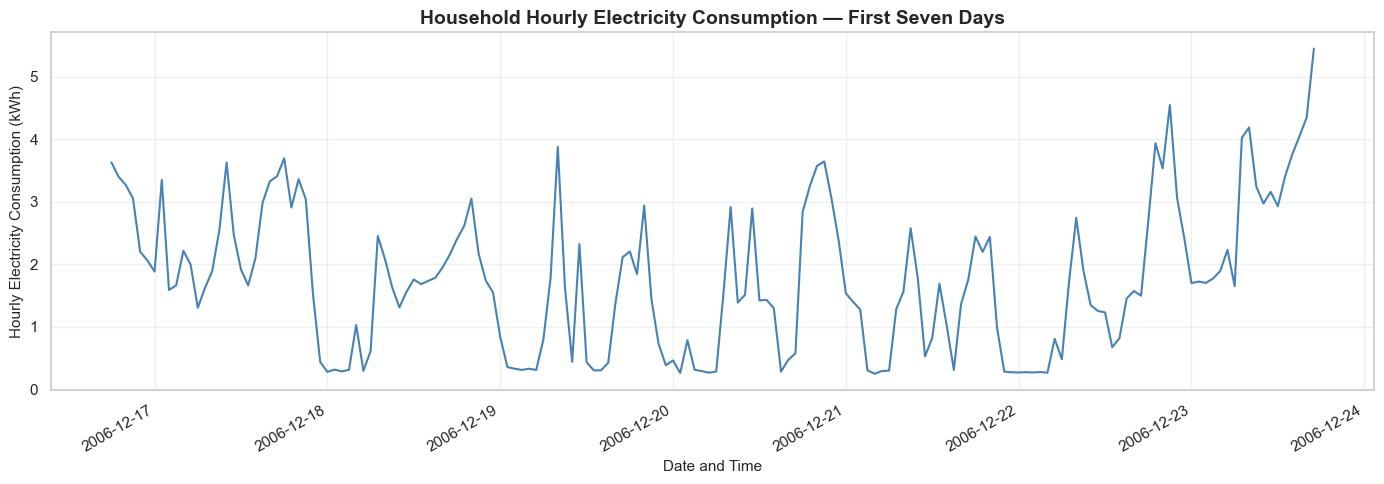

Hourly Electricity Consumption Visualization
---------------------------------------------
Complete hourly observations plotted: 168
Start date: 2006-12-16 18:00:00
End date: 2006-12-23 18:00:00
Average hourly consumption: 1.771 kWh
Maximum hourly consumption: 5.453 kWh
Minimum hourly consumption: 0.247 kWh


In [18]:
# Phase 4 - Step 4.10: Hourly Electricity Consumption Trends

import matplotlib.pyplot as plt
import pandas as pd

# Select only complete hourly observations
hourly_valid = df_hourly.loc[
    df_hourly["Complete_Hour"] &
    df_hourly["Energy_kWh"].notna()
].copy()

# Select the first seven days of available complete-hour data
start_time = hourly_valid.index.min()
end_time = start_time + pd.Timedelta(days=7)

weekly_sample = hourly_valid.loc[
    (hourly_valid.index >= start_time) &
    (hourly_valid.index < end_time)
]

# Create the visualization
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    weekly_sample.index,
    weekly_sample["Energy_kWh"],
    color="steelblue",
    linewidth=1.5
)

ax.set_title(
    "Household Hourly Electricity Consumption — First Seven Days",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Date and Time", fontsize=11)
ax.set_ylabel("Hourly Electricity Consumption (kWh)", fontsize=11)

ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()

# Save visualization to the project's figure folder
fig.savefig(
    "../figure/hourly_electricity_consumption_first_week.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display summary information
print("Hourly Electricity Consumption Visualization")
print("-" * 45)
print(f"Complete hourly observations plotted: {len(weekly_sample):,}")
print(f"Start date: {start_time}")
print(f"End date: {end_time}")
print(f"Average hourly consumption: {weekly_sample['Energy_kWh'].mean():.3f} kWh")
print(f"Maximum hourly consumption: {weekly_sample['Energy_kWh'].max():.3f} kWh")
print(f"Minimum hourly consumption: {weekly_sample['Energy_kWh'].min():.3f} kWh")

#### Interpretation of Hourly Electricity Consumption

The first seven days of complete hourly electricity consumption
observations reveal substantial fluctuations in household energy use.

Across the 168 hourly observations, average electricity consumption
was approximately 1.771 kWh per hour, with a minimum of 0.247 kWh
and a maximum of 5.453 kWh.

The time-series visualization shows alternating periods of relatively
low electricity consumption and pronounced consumption peaks.

These variations may reflect differences in household activity,
appliance usage, and daily electricity demand.

However, the observed patterns cannot be attributed to specific
household activities without additional contextual information.

The results demonstrate the importance of examining daily and
weekly consumption patterns to better understand electricity demand
and support subsequent forecasting analysis.

### 4.11 Daily Electricity Consumption Analysis

This section examines daily household electricity consumption by
aggregating the previously calculated hourly energy measurements.

Daily energy consumption is expressed in kilowatt-hours (kWh).

To ensure reliable daily totals, a day is considered complete only
when all 24 hourly intervals contain valid energy measurements.

Incomplete days are retained for data-quality assessment but
excluded from calculations requiring complete daily consumption.

The analysis provides a foundation for identifying daily consumption
patterns, variability, and longer-term electricity demand trends.

In [19]:
# Phase 4 - Step 4.11: Daily Electricity Consumption Analysis

import pandas as pd

# Identify valid hourly energy observations
valid_hourly_energy = df_hourly["Energy_kWh"].where(
    df_hourly["Complete_Hour"]
)

# Aggregate hourly energy into daily totals
df_daily = pd.DataFrame({
    "Energy_kWh": valid_hourly_energy.resample("D").sum(min_count=24),
    "Valid_Hours": valid_hourly_energy.resample("D").count()
})

# Identify days with all 24 valid hourly observations
df_daily["Complete_Day"] = df_daily["Valid_Hours"].eq(24)

# Explicitly exclude incomplete days from daily energy totals
df_daily.loc[
    ~df_daily["Complete_Day"], "Energy_kWh"
] = float("nan")

# Summarize daily data quality
total_days = len(df_daily)
complete_days = int(df_daily["Complete_Day"].sum())
incomplete_days = total_days - complete_days

print("Daily Electricity Consumption Aggregation")
print("-" * 50)

print(f"Total calendar days: {total_days:,}")
print(f"Complete days: {complete_days:,}")
print(f"Incomplete days: {incomplete_days:,}")

print(
    f"Daily completeness rate: "
    f"{complete_days / total_days * 100:.2f}%"
)

print("\nFirst ten daily observations:")
display(df_daily.head(10))

# Validate daily aggregation
print("\nDaily Aggregation Validation")
print("-" * 50)

print(
    "All complete days contain 24 valid hours:",
    df_daily.loc[
        df_daily["Complete_Day"], "Valid_Hours"
    ].eq(24).all()
)

print(
    "Incomplete days have missing daily energy:",
    df_daily.loc[
        ~df_daily["Complete_Day"], "Energy_kWh"
    ].isna().all()
)

print(
    "Complete days have valid daily energy:",
    df_daily.loc[
        df_daily["Complete_Day"], "Energy_kWh"
    ].notna().all()
)

Daily Electricity Consumption Aggregation
--------------------------------------------------
Total calendar days: 1,442
Complete days: 1,410
Incomplete days: 32
Daily completeness rate: 97.78%

First ten daily observations:


,Energy_kWh,Valid_Hours,Complete_Day
Datetime,,,
2006-12-16,NaN,6,False
2006-12-17,56.507667,24,True
2006-12-18,36.730433,24,True
2006-12-19,27.769900,24,True
2006-12-20,37.095800,24,True
2006-12-21,28.618567,24,True
2006-12-22,39.022300,24,True
2006-12-23,79.556433,24,True
2006-12-24,42.500200,24,True



Daily Aggregation Validation
--------------------------------------------------
All complete days contain 24 valid hours: True
Incomplete days have missing daily energy: True
Complete days have valid daily energy: True



### 4.12 Daily Electricity Consumption Trends

This section visualizes daily household electricity consumption
across the complete observation period.

Only days containing 24 valid hourly energy measurements are
included in the analysis.

The visualization examines long-term consumption variability,
periods of elevated electricity demand, and potential changes
in household electricity usage over time.

A 30-day rolling average is included to highlight longer-term
patterns while reducing short-term fluctuations.


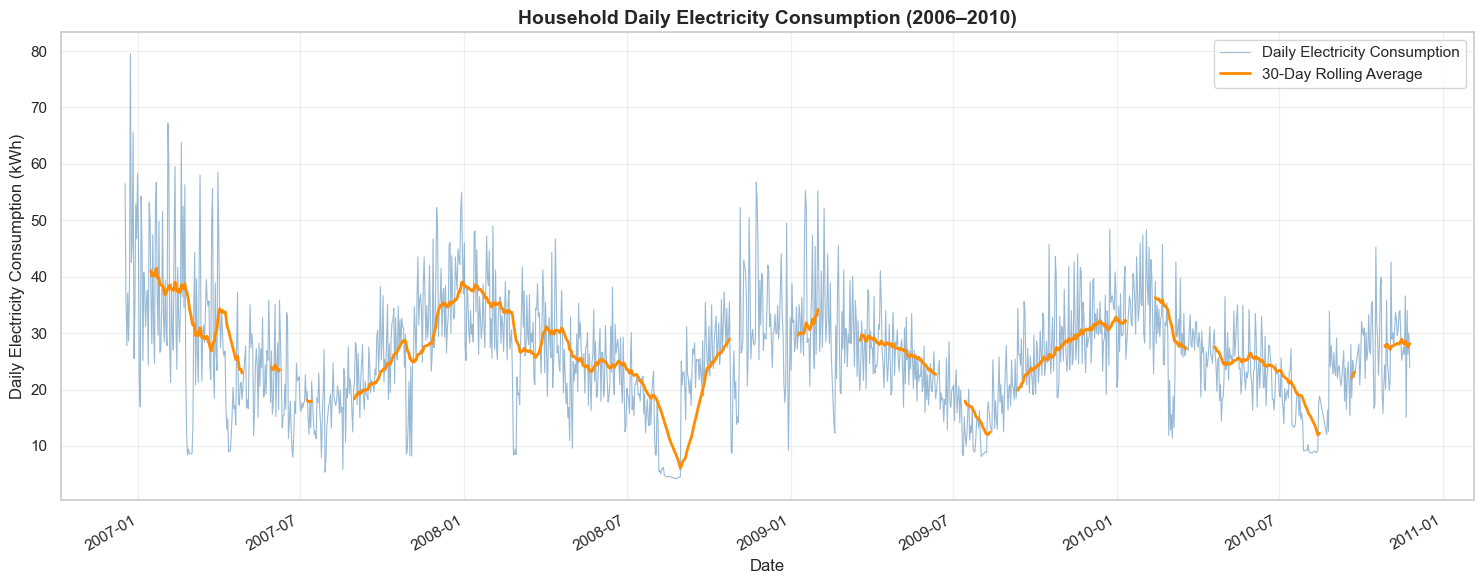

Daily Electricity Consumption Summary
---------------------------------------------
Complete days analyzed: 1,410
Average daily consumption: 26.202 kWh
Median daily consumption: 25.937 kWh
Maximum daily consumption: 79.556 kWh
Minimum daily consumption: 4.172 kWh
Standard deviation: 10.009 kWh


In [20]:

# Phase 4 - Step 4.12: Daily Electricity Consumption Trends

import matplotlib.pyplot as plt

# Select complete daily energy observations
daily_valid = df_daily.loc[
    df_daily["Complete_Day"], "Energy_kWh"
].copy()

# Calculate a 30-day rolling average
# Require at least 30 valid daily observations
daily_rolling_30 = df_daily["Energy_kWh"].rolling(
    window=30,
    min_periods=30
).mean()

# Create the visualization
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    daily_valid.index,
    daily_valid,
    color="steelblue",
    linewidth=0.8,
    alpha=0.55,
    label="Daily Electricity Consumption"
)

ax.plot(
    daily_rolling_30.index,
    daily_rolling_30,
    color="darkorange",
    linewidth=2,
    label="30-Day Rolling Average"
)

ax.set_title(
    "Household Daily Electricity Consumption (2006–2010)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("Daily Electricity Consumption (kWh)")

ax.grid(True, alpha=0.3)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()

# Export the figure
fig.savefig(
    "../figure/daily_electricity_consumption_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display descriptive statistics
print("Daily Electricity Consumption Summary")
print("-" * 45)
print(f"Complete days analyzed: {len(daily_valid):,}")
print(f"Average daily consumption: {daily_valid.mean():.3f} kWh")
print(f"Median daily consumption: {daily_valid.median():.3f} kWh")
print(f"Maximum daily consumption: {daily_valid.max():.3f} kWh")
print(f"Minimum daily consumption: {daily_valid.min():.3f} kWh")
print(f"Standard deviation: {daily_valid.std():.3f} kWh")



### 4.13 Daily Electricity Consumption by Day of the Week

This section investigates variations in household electricity
consumption across the seven days of the week.

Only complete daily observations are included to ensure that
missing measurements do not underestimate electricity usage.

The analysis compares average daily electricity consumption
from Monday to Sunday and provides an initial assessment of
weekday and weekend consumption patterns.


In [21]:

# Phase 4 - Step 4.13: Day-of-Week Consumption Analysis

import pandas as pd

# Use only complete daily observations
daily_weekday = df_daily.loc[
    df_daily["Complete_Day"], ["Energy_kWh"]
].copy()

# Extract day-of-week information
daily_weekday["Day_of_Week"] = daily_weekday.index.day_name()

# Define chronological weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Calculate descriptive statistics by weekday
weekday_summary = (
    daily_weekday.groupby("Day_of_Week")["Energy_kWh"]
    .agg(["count", "mean", "median", "std"])
    .reindex(weekday_order)
)

# Rename columns for readability
weekday_summary.columns = [
    "Number_of_Days",
    "Mean_kWh",
    "Median_kWh",
    "Std_kWh"
]

print("Daily Electricity Consumption by Day of the Week")
print("-" * 55)

display(weekday_summary.round(3))

# Identify highest and lowest average consumption days
highest_day = weekday_summary["Mean_kWh"].idxmax()
lowest_day = weekday_summary["Mean_kWh"].idxmin()

print(f"\nHighest average consumption: {highest_day}")
print(f"Lowest average consumption: {lowest_day}")



Daily Electricity Consumption by Day of the Week
-------------------------------------------------------


,Number_of_Days,Mean_kWh,Median_kWh,Std_kWh
Day_of_Week,,,,
Monday,202,23.965,24.132,8.382
Tuesday,202,25.726,25.875,9.342
Wednesday,202,25.971,26.386,9.099
Thursday,203,23.532,23.264,8.377
Friday,204,25.028,25.022,8.254
Saturday,198,30.009,29.344,12.290
Sunday,199,29.329,27.992,11.780



Highest average consumption: Saturday
Lowest average consumption: Thursday



### 4.14 Visualization of Daily Electricity Consumption by Day of the Week

This section visualizes average household electricity consumption
for each day of the week.

The analysis uses complete daily observations to avoid
underestimating consumption due to missing measurements.

The visualization highlights differences between weekday and
weekend electricity demand.


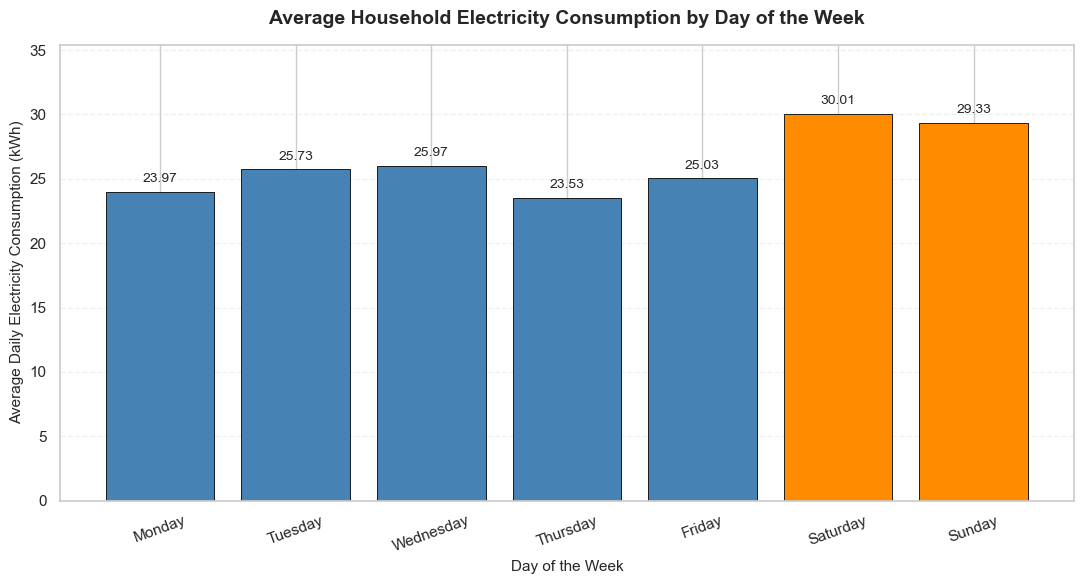

Weekday consumption visualization completed.
Figure saved to: ..\figure\weekday_electricity_consumption.png


In [22]:

# Phase 4 - Step 4.14: Weekday Electricity Consumption Visualization

import matplotlib.pyplot as plt
from pathlib import Path

# Prepare average consumption values
weekday_means = weekday_summary["Mean_kWh"]

# Highlight Saturday and Sunday
bar_colors = [
    "steelblue" if day not in ["Saturday", "Sunday"]
    else "darkorange"
    for day in weekday_means.index
]

# Create visualization
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    weekday_means.index,
    weekday_means.values,
    color=bar_colors,
    edgecolor="black",
    linewidth=0.6
)

# Add consumption values above bars
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10
    )

# Chart formatting
ax.set_title(
    "Average Household Electricity Consumption by Day of the Week",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Day of the Week", fontsize=11)
ax.set_ylabel("Average Daily Electricity Consumption (kWh)", fontsize=11)

ax.set_ylim(0, weekday_means.max() * 1.18)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=20)
plt.tight_layout()

# Save figure to the project figure folder
figure_path = Path("../figure/weekday_electricity_consumption.png")
figure_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Weekday consumption visualization completed.")
print(f"Figure saved to: {figure_path}")



### 4.15 Weekday versus Weekend Electricity Consumption Analysis

This section compares average daily household electricity
consumption between weekdays (Monday–Friday) and weekends
(Saturday–Sunday).

Only complete daily observations are considered.

The analysis calculates the average, median, standard deviation,
and percentage difference in electricity consumption between
the two groups.


In [23]:

# Phase 4 - Step 4.15: Weekday vs Weekend Analysis

# Create an independent working copy
weekend_analysis = daily_weekday.copy()

# Classify each observation
weekend_analysis["Day_Type"] = (
    weekend_analysis.index.dayofweek
    .map(lambda day: "Weekend" if day >= 5 else "Weekday")
)

# Calculate descriptive statistics
weekend_summary = (
    weekend_analysis.groupby("Day_Type")["Energy_kWh"]
    .agg(["count", "mean", "median", "std"])
    .reindex(["Weekday", "Weekend"])
)

weekend_summary.columns = [
    "Number_of_Days",
    "Mean_kWh",
    "Median_kWh",
    "Std_kWh"
]

print("Weekday versus Weekend Electricity Consumption")
print("-" * 55)

display(weekend_summary.round(3))

# Calculate the difference in average consumption
weekday_mean = weekend_summary.loc["Weekday", "Mean_kWh"]
weekend_mean = weekend_summary.loc["Weekend", "Mean_kWh"]

absolute_difference = weekend_mean - weekday_mean

percentage_difference = (
    absolute_difference / weekday_mean
) * 100

print(f"\nWeekday average: {weekday_mean:.3f} kWh")
print(f"Weekend average: {weekend_mean:.3f} kWh")

print(
    f"Absolute difference: {absolute_difference:.3f} kWh"
)

print(
    f"Percentage difference: {percentage_difference:.2f}%"
)

print(
    "\nHigher average consumption:",
    "Weekend" if weekend_mean > weekday_mean else "Weekday"
)


Weekday versus Weekend Electricity Consumption
-------------------------------------------------------


,Number_of_Days,Mean_kWh,Median_kWh,Std_kWh
Day_Type,,,,
Weekday,1013,24.843,24.749,8.736
Weekend,397,29.668,28.612,12.027



Weekday average: 24.843 kWh
Weekend average: 29.668 kWh
Absolute difference: 4.825 kWh
Percentage difference: 19.42%

Higher average consumption: Weekend



### 4.16 Visualization of Weekday versus Weekend Electricity Consumption

This section compares average daily household electricity
consumption between weekdays and weekends.

The visualization highlights the percentage difference in
average consumption and supports interpretation of household
electricity demand patterns.

Only complete daily observations are included.


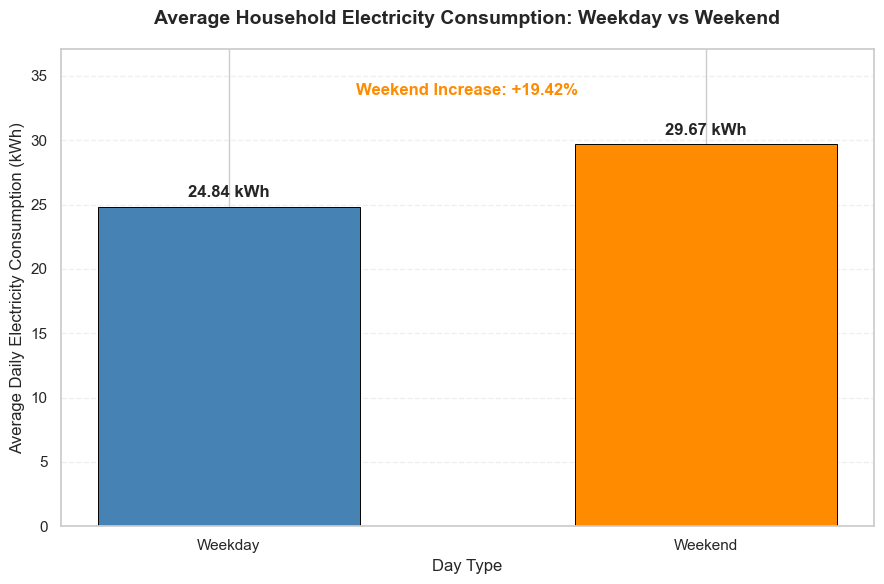

Weekday vs Weekend visualization completed.
Figure saved to: ..\figure\weekday_vs_weekend_consumption.png


In [24]:

# Phase 4 - Step 4.16: Weekday vs Weekend Visualization

import matplotlib.pyplot as plt
from pathlib import Path

# Prepare summary data
categories = ["Weekday", "Weekend"]
mean_values = weekend_summary.loc[categories, "Mean_kWh"]

# Create figure
fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    categories,
    mean_values,
    color=["steelblue", "darkorange"],
    edgecolor="black",
    width=0.55,
    linewidth=0.7
)

# Add values above each bar
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f} kWh",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

# Display percentage difference
ax.text(
    0.5,
    max(mean_values) * 1.13,
    f"Weekend Increase: {percentage_difference:+.2f}%",
    ha="center",
    fontsize=12,
    fontweight="bold",
    color="darkorange"
)

# Formatting
ax.set_title(
    "Average Household Electricity Consumption: Weekday vs Weekend",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_ylabel("Average Daily Electricity Consumption (kWh)")
ax.set_xlabel("Day Type")

ax.set_ylim(0, max(mean_values) * 1.25)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Save visualization
figure_path = Path("../figure/weekday_vs_weekend_consumption.png")
figure_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Weekday vs Weekend visualization completed.")
print(f"Figure saved to: {figure_path}")


### Monthly Electricity Consumption Analysis

This section investigates monthly variations in household electricity consumption between December 2006 and November 2010.

The analysis uses complete daily electricity consumption records to calculate monthly average daily consumption. This approach allows meaningful comparisons between months while avoiding misleading totals caused by missing observations or differences in month length.

The objectives are to:
- Identify months with higher and lower average electricity consumption.
- Examine changes in household electricity demand across the study period.
- Establish a foundation for subsequent seasonal consumption analysis.

In [29]:

# Phase 4 - Monthly Electricity Consumption Analysis
# Step 4.17: Calculate monthly consumption statistics

import pandas as pd

# Select only complete days with valid electricity consumption
daily_valid = df_daily.loc[
    df_daily["Complete_Day"] &
    df_daily["Energy_kWh"].notna(),
    ["Energy_kWh"]
].copy()

# Group daily electricity consumption by calendar month
monthly_summary = daily_valid.resample("MS").agg(
    Total_Energy_kWh=("Energy_kWh", "sum"),
    Average_Daily_kWh=("Energy_kWh", "mean"),
    Median_Daily_kWh=("Energy_kWh", "median"),
    Std_Daily_kWh=("Energy_kWh", "std"),
    Complete_Days=("Energy_kWh", "count")
)

# Count calendar days in each month within the dataset's date range
calendar_days = (
    df_daily["Energy_kWh"]
    .resample("MS")
    .size()
)

monthly_summary["Calendar_Days"] = calendar_days

# Calculate monthly data completeness
monthly_summary["Completeness_Percent"] = (
    monthly_summary["Complete_Days"]
    / monthly_summary["Calendar_Days"]
    * 100
)

# Exclude months with no complete daily observations
monthly_summary = monthly_summary.loc[
    monthly_summary["Complete_Days"] > 0
].copy()

print("Monthly Electricity Consumption Summary")
print("-" * 55)

print(f"Months analyzed: {len(monthly_summary):,}")
print(f"Complete daily observations: {len(daily_valid):,}")

print("\nFirst 12 monthly observations:")
display(monthly_summary.head(12).round(2))

print("\nLast 12 monthly observations:")
display(monthly_summary.tail(12).round(2))

print(
    f"\nAverage monthly data completeness: "
    f"{monthly_summary['Completeness_Percent'].mean():.2f}%"
)


Monthly Electricity Consumption Summary
-------------------------------------------------------
Months analyzed: 48
Complete daily observations: 1,410

First 12 monthly observations:


,Total_Energy_kWh,Average_Daily_kWh,Median_Daily_kWh,Std_Daily_kWh,Complete_Days,Calendar_Days,Completeness_Percent
Datetime,,,,,,,
2006-12-01,676.96,45.13,42.50,15.16,15,16,93.75
2007-01-01,1150.29,37.11,35.91,11.01,31,31,100.00
2007-02-01,941.61,33.63,30.85,17.28,28,28,100.00
2007-03-01,981.05,31.65,31.41,12.97,31,31,100.00
2007-04-01,578.97,21.44,18.24,9.32,27,30,90.00
2007-05-01,733.48,23.66,24.46,6.08,31,31,100.00
2007-06-01,577.15,19.90,17.87,7.59,29,30,96.67
2007-07-01,479.81,15.99,16.62,4.69,30,31,96.77
2007-08-01,550.61,18.35,18.65,4.20,30,31,96.77



Last 12 monthly observations:


,Total_Energy_kWh,Average_Daily_kWh,Median_Daily_kWh,Std_Daily_kWh,Complete_Days,Calendar_Days,Completeness_Percent
Datetime,,,,,,,
2009-12-01,1015.16,32.75,33.45,5.92,31,31,100.00
2010-01-01,958.08,34.22,34.80,6.59,28,31,90.32
2010-02-01,924.62,33.02,32.51,7.73,28,28,100.00
2010-03-01,785.11,27.07,27.72,7.34,29,31,93.55
2010-04-01,739.64,24.65,25.84,4.39,30,30,100.00
2010-05-01,814.90,26.29,25.28,4.78,31,31,100.00
2010-06-01,698.13,23.27,23.15,4.62,30,30,100.00
2010-07-01,536.51,17.31,18.06,4.48,31,31,100.00
2010-08-01,350.53,14.02,9.26,7.28,25,31,80.65



Average monthly data completeness: 97.73%


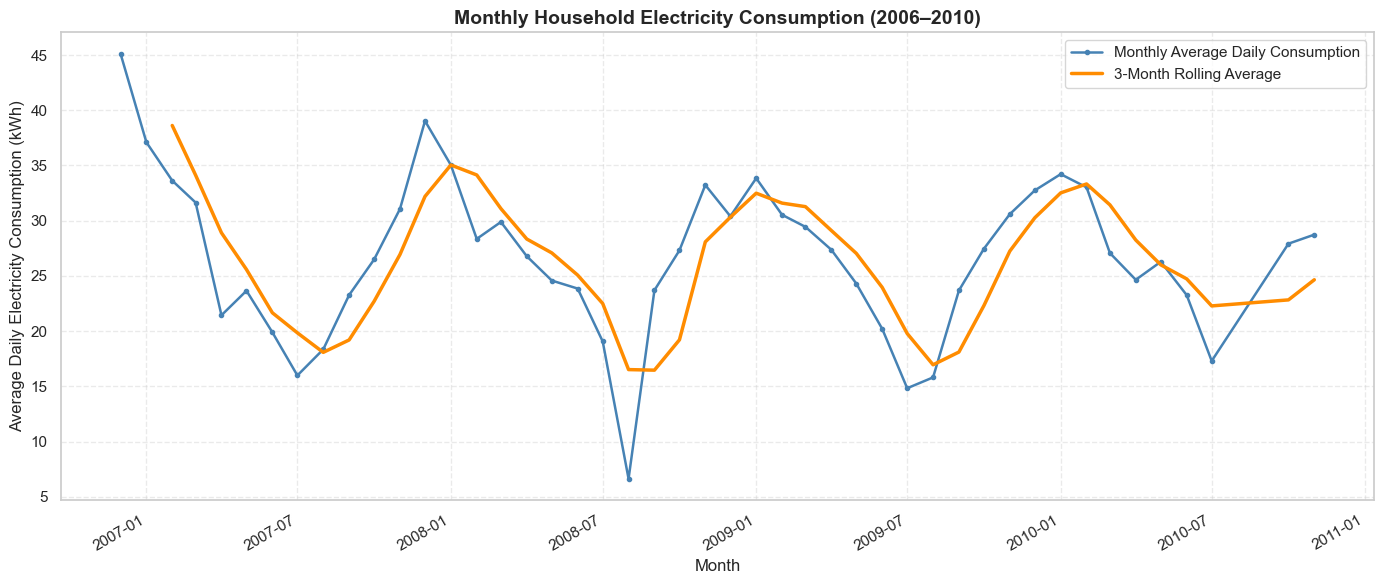

Monthly Electricity Consumption Visualization
--------------------------------------------------
Months included in visualization: 46
Months excluded (below 90% completeness): 2
Figure saved to: ../figure/monthly_electricity_consumption.png


In [30]:

# Step 4.18 - Monthly Electricity Consumption Visualization

import matplotlib.pyplot as plt

# Use average daily consumption for monthly comparisons
monthly_plot = monthly_summary[
    monthly_summary["Completeness_Percent"] >= 90
].copy()

# Calculate a 3-month rolling average
monthly_plot["Rolling_3_Months"] = (
    monthly_plot["Average_Daily_kWh"]
    .rolling(window=3, min_periods=3)
    .mean()
)

# Create visualization
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    monthly_plot.index,
    monthly_plot["Average_Daily_kWh"],
    color="steelblue",
    linewidth=1.8,
    marker="o",
    markersize=3,
    label="Monthly Average Daily Consumption"
)

ax.plot(
    monthly_plot.index,
    monthly_plot["Rolling_3_Months"],
    color="darkorange",
    linewidth=2.5,
    label="3-Month Rolling Average"
)

ax.set_title(
    "Monthly Household Electricity Consumption (2006–2010)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Average Daily Electricity Consumption (kWh)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)

fig.autofmt_xdate()
plt.tight_layout()

# Save figure
plt.savefig(
    "../figure/monthly_electricity_consumption.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Monthly Electricity Consumption Visualization")
print("-" * 50)
print(f"Months included in visualization: {len(monthly_plot)}")
print(f"Months excluded (below 90% completeness): {len(monthly_summary) - len(monthly_plot)}")
print("Figure saved to: ../figure/monthly_electricity_consumption.png")



### Interpretation of Monthly Electricity Consumption

The monthly electricity consumption analysis reveals substantial variation in household electricity demand between December 2006 and November 2010.

**Key findings:**

1. **Seasonal consumption patterns:** Average daily electricity consumption generally increases during colder months and decreases during warmer months, suggesting a possible relationship between electricity demand and seasonal household activities.

2. **Recurring annual variation:** Similar consumption patterns occur across multiple years, indicating that seasonal effects may contribute to changes in electricity demand.

3. **Unusual consumption periods:** A pronounced reduction in electricity consumption is visible during 2008. Further investigation is required to determine whether this reflects household behavior, data availability, or other factors.

4. **Data completeness:** Of the 48 calendar months represented in the dataset, 46 satisfied the minimum 90% completeness threshold used for visualization.

**Analytical implication:**

The recurring monthly patterns suggest that calendar-related features, particularly month and season, may be useful predictors in subsequent electricity demand forecasting models. However, these relationships should be evaluated quantitatively before drawing firm conclusions.


### Seasonal Electricity Consumption Analysis

This section examines how household electricity consumption varies across the four meteorological seasons: winter, spring, summer, and autumn.

The analysis uses complete daily electricity consumption records to calculate seasonal averages, medians, standard deviations, and observation counts.

The objectives are to:
- Compare average daily electricity consumption across seasons.
- Identify the seasons with the highest and lowest electricity demand.
- Examine variability in household electricity consumption.
- Assess whether seasonal patterns may be useful for electricity demand forecasting.

In [31]:

# Step 4.19 - Seasonal Electricity Consumption Statistics

import pandas as pd

# Use complete daily electricity consumption records
seasonal_daily = daily_valid[["Energy_kWh"]].copy()

# Extract calendar month
seasonal_daily["Month"] = seasonal_daily.index.month

# Assign meteorological seasons
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

seasonal_daily["Season"] = seasonal_daily["Month"].map(season_map)

# Define logical season order
season_order = ["Winter", "Spring", "Summer", "Autumn"]

# Calculate seasonal statistics
seasonal_summary = (
    seasonal_daily.groupby("Season")["Energy_kWh"]
    .agg(
        Number_of_Days="count",
        Mean_kWh="mean",
        Median_kWh="median",
        Std_kWh="std",
        Minimum_kWh="min",
        Maximum_kWh="max"
    )
    .reindex(season_order)
)

print("Seasonal Electricity Consumption Summary")
print("-" * 55)

display(seasonal_summary.round(3))

# Identify highest and lowest average consumption
highest_season = seasonal_summary["Mean_kWh"].idxmax()
lowest_season = seasonal_summary["Mean_kWh"].idxmin()

print(f"\nHighest average consumption: {highest_season}")
print(f"Lowest average consumption: {lowest_season}")

print(
    f"Difference between highest and lowest seasonal averages: "
    f"{seasonal_summary['Mean_kWh'].max() - seasonal_summary['Mean_kWh'].min():.3f} kWh"
)

print(
    f"\nTotal complete days analyzed: "
    f"{seasonal_summary['Number_of_Days'].sum():,}"
)


Seasonal Electricity Consumption Summary
-------------------------------------------------------


,Number_of_Days,Mean_kWh,Median_kWh,Std_kWh,Minimum_kWh,Maximum_kWh
Season,,,,,,
Winter,339,34.043,33.005,10.328,8.362,79.556
Spring,363,26.482,26.332,7.530,8.595,58.492
Summer,355,17.425,17.870,6.769,4.172,38.152
Autumn,353,27.211,26.292,7.496,8.209,56.790



Highest average consumption: Winter
Lowest average consumption: Summer
Difference between highest and lowest seasonal averages: 16.618 kWh

Total complete days analyzed: 1,410


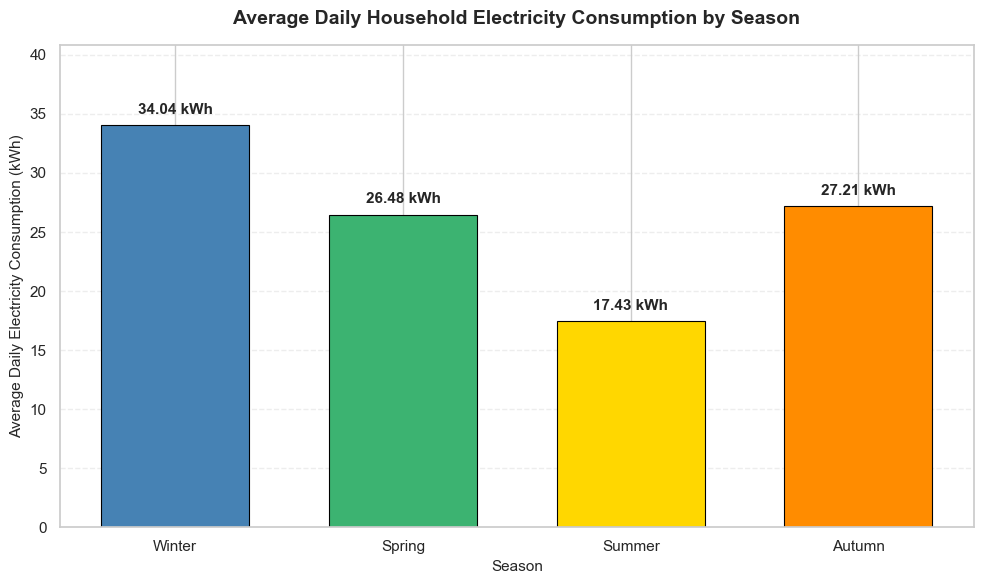

Seasonal electricity consumption visualization completed.
Figure saved to: ../figure/seasonal_electricity_consumption.png


In [32]:

# Step 4.20 - Seasonal Electricity Consumption Visualization

import matplotlib.pyplot as plt

# Extract seasonal averages
seasons = seasonal_summary.index
average_consumption = seasonal_summary["Mean_kWh"]

# Assign colors to the four seasons
colors = ["steelblue", "mediumseagreen", "gold", "darkorange"]

# Create the figure
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    seasons,
    average_consumption,
    color=colors,
    edgecolor="black",
    linewidth=0.8,
    width=0.65
)

# Add values above each bar
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f} kWh",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Chart formatting
ax.set_title(
    "Average Daily Household Electricity Consumption by Season",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Season", fontsize=11)
ax.set_ylabel("Average Daily Electricity Consumption (kWh)", fontsize=11)

ax.set_ylim(0, average_consumption.max() * 1.2)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

plt.tight_layout()

# Save figure
plt.savefig(
    "../figure/seasonal_electricity_consumption.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Seasonal electricity consumption visualization completed.")
print("Figure saved to: ../figure/seasonal_electricity_consumption.png")


### 4.21 Interpretation of Seasonal Electricity Consumption

The seasonal analysis reveals substantial variation in household electricity consumption throughout the year.

**Key findings:**

- **Winter:** Average daily electricity consumption is highest at **34.04 kWh**, suggesting increased demand for household electrical appliances during colder months.
- **Spring:** Average daily consumption decreases to **26.48 kWh**, indicating a transition toward lower electricity demand.
- **Summer:** Average daily consumption reaches its lowest level at **17.43 kWh**, potentially reflecting reduced use of heating-related electrical appliances.
- **Autumn:** Average daily consumption increases to **27.21 kWh**, suggesting electricity demand begins rising as temperatures decline.

**Seasonal variation:**

The difference between winter and summer average daily consumption is approximately **16.62 kWh**, with winter consumption approximately **95.4% higher** than summer consumption.

**Implications for electricity demand forecasting:**

These findings suggest that seasonal information may be valuable when developing electricity demand forecasting models. Calendar-based features, such as month and season, could help capture recurring variations in household electricity consumption.

However, the dataset does not contain weather measurements or appliance-level heating information sufficient to establish the exact causes of these seasonal differences.

**Conclusion:**

Seasonal electricity consumption patterns should be considered during feature engineering and model development to improve the representation of long-term demand variations.

## 5. Hourly Electricity Consumption Pattern Analysis

### 5.1 Average Electricity Consumption by Hour of Day

This section investigates how household electricity consumption varies throughout a typical 24-hour period.

The analysis uses complete hourly observations from the cleaned dataset to identify recurring electricity demand patterns.

**Objectives:**
- Calculate average electricity consumption for each hour of the day.
- Identify peak electricity consumption hours.
- Identify periods of relatively low electricity consumption.
- Examine daily demand patterns relevant to electricity forecasting.

In [33]:
# Section 5.1.1 - Average Electricity Consumption by Hour of Day

import pandas as pd

# Select only complete hourly observations
hourly_complete = df_hourly.loc[
    df_hourly["Complete_Hour"] & df_hourly["Energy_kWh"].notna()
].copy()

# Extract the hour of the day (0 to 23)
hourly_complete["Hour_of_Day"] = hourly_complete.index.hour

# Calculate average electricity consumption for each hour
hourly_profile = (
    hourly_complete.groupby("Hour_of_Day")["Energy_kWh"]
    .agg(["count", "mean", "median", "std"])
    .rename(columns={
        "count": "Number_of_Hours",
        "mean": "Mean_kWh",
        "median": "Median_kWh",
        "std": "Std_kWh"
    })
    .reindex(range(24))
)

# Display the hourly consumption summary
print("Average Household Electricity Consumption by Hour of Day")
print("-" * 60)

display(hourly_profile.round(3))

# Identify peak and off-peak consumption hours
peak_hour = hourly_profile["Mean_kWh"].idxmax()
lowest_hour = hourly_profile["Mean_kWh"].idxmin()

print(f"\nPeak consumption hour: {peak_hour:02d}:00")
print(f"Average consumption at peak hour: {hourly_profile.loc[peak_hour, 'Mean_kWh']:.3f} kWh")

print(f"\nLowest consumption hour: {lowest_hour:02d}:00")
print(f"Average consumption at lowest hour: {hourly_profile.loc[lowest_hour, 'Mean_kWh']:.3f} kWh")

Average Household Electricity Consumption by Hour of Day
------------------------------------------------------------


,Number_of_Hours,Mean_kWh,Median_kWh,Std_kWh
Hour_of_Day,,,,
0,1424,0.659,0.392,0.618
1,1424,0.539,0.347,0.501
2,1424,0.481,0.332,0.410
3,1422,0.445,0.325,0.357
4,1422,0.444,0.325,0.344
5,1421,0.454,0.323,0.354
6,1421,0.792,0.679,0.513
7,1421,1.502,1.580,0.894
8,1421,1.461,1.488,0.753



Peak consumption hour: 20:00
Average consumption at peak hour: 1.899 kWh

Lowest consumption hour: 04:00
Average consumption at lowest hour: 0.444 kWh


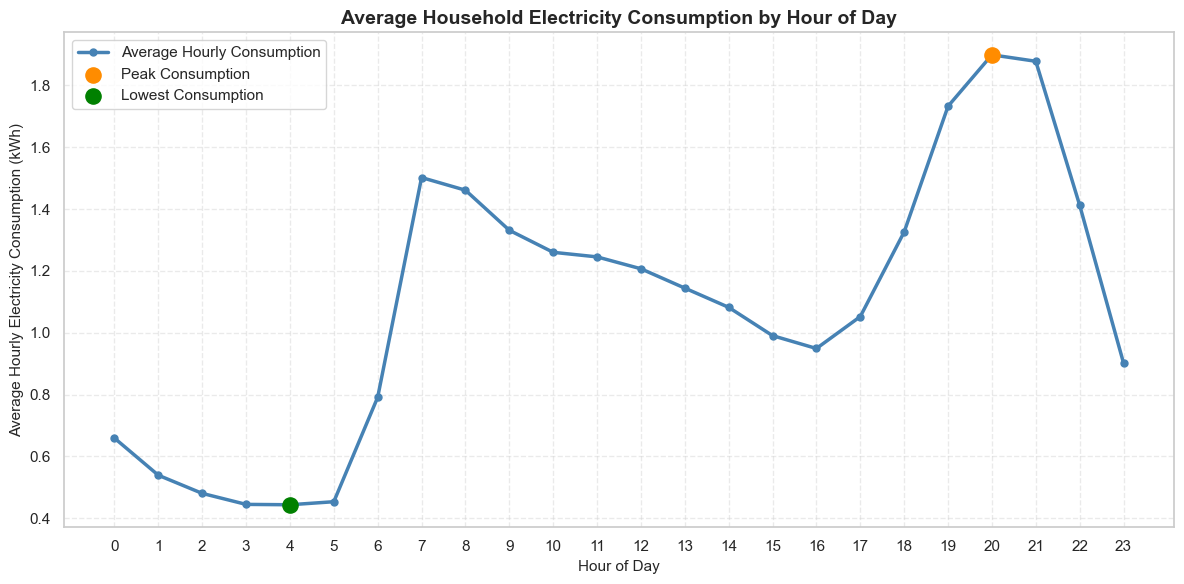

Hourly consumption profile visualization completed.
Figure saved to: ../figure/hourly_consumption_profile.png


In [34]:
# Section 5.1.2 - Hourly Electricity Consumption Profile

import matplotlib.pyplot as plt

# Average consumption for each hour
hours = hourly_profile.index
average_consumption = hourly_profile["Mean_kWh"]

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    hours,
    average_consumption,
    color="steelblue",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="Average Hourly Consumption"
)

# Highlight peak consumption
ax.scatter(
    peak_hour,
    average_consumption.loc[peak_hour],
    color="darkorange",
    s=120,
    zorder=5,
    label="Peak Consumption"
)

# Highlight minimum consumption
ax.scatter(
    lowest_hour,
    average_consumption.loc[lowest_hour],
    color="green",
    s=120,
    zorder=5,
    label="Lowest Consumption"
)

ax.set_title(
    "Average Household Electricity Consumption by Hour of Day",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Hour of Day", fontsize=11)
ax.set_ylabel("Average Hourly Electricity Consumption (kWh)", fontsize=11)

ax.set_xticks(range(24))
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()

# Save the figure
plt.savefig(
    "../figure/hourly_consumption_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Hourly consumption profile visualization completed.")
print("Figure saved to: ../figure/hourly_consumption_profile.png")

### Interpretation of the Hourly Electricity Consumption Profile

The hourly electricity consumption profile reveals a distinct daily
demand pattern, characterized by morning and evening consumption peaks.

- **Early morning:** Electricity consumption is lowest at 04:00,
  averaging 0.444 kWh per hour.
- **Morning:** Consumption increases substantially between 06:00
  and 08:00, suggesting increased household activity.
- **Afternoon:** Electricity consumption gradually declines from
  the morning peak.
- **Evening:** Consumption increases again, reaching its highest
  average value of 1.899 kWh at 20:00.

The observed pattern suggests that household electricity demand
is influenced by daily routines and appliance usage.

These time-dependent consumption characteristics provide useful
information for feature engineering and electricity demand forecasting.

## 5.2 Weekday vs. Weekend Hourly Electricity Consumption

This section compares hourly household electricity consumption
patterns between weekdays (Monday–Friday) and weekends
(Saturday–Sunday).

The objective is to identify differences in electricity demand
throughout the day and determine whether day type influences
the timing of peak household electricity consumption.

In [35]:
# Section 5.2.1 - Weekday vs Weekend Hourly Consumption

# Reuse the complete hourly observations from Section 5.1
hourly_daytype = hourly_complete.copy()

# Identify weekdays and weekends
hourly_daytype["Day_of_Week"] = hourly_daytype.index.dayofweek

hourly_daytype["Day_Type"] = hourly_daytype["Day_of_Week"].map(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)

# Calculate mean hourly consumption for each day type
hourly_daytype_profile = (
    hourly_daytype
    .groupby(["Hour_of_Day", "Day_Type"])["Energy_kWh"]
    .mean()
    .unstack("Day_Type")
    .reindex(range(24))
)

# Display results
print("Weekday vs Weekend Hourly Electricity Consumption")
print("-" * 60)

display(hourly_daytype_profile.round(3))

# Identify peak consumption hours
for day_type in ["Weekday", "Weekend"]:
    peak_hour = hourly_daytype_profile[day_type].idxmax()
    peak_value = hourly_daytype_profile.loc[peak_hour, day_type]

    print(
        f"{day_type} peak hour: {peak_hour:02d}:00 "
        f"| Average consumption: {peak_value:.3f} kWh"
    )

Weekday vs Weekend Hourly Electricity Consumption
------------------------------------------------------------


Day_Type,Weekday,Weekend
Hour_of_Day,,
0,0.569,0.890
1,0.468,0.721
2,0.435,0.596
3,0.412,0.530
4,0.426,0.490
5,0.431,0.512
6,0.875,0.579
7,1.715,0.961
8,1.580,1.158


Weekday peak hour: 21:00 | Average consumption: 1.856 kWh
Weekend peak hour: 19:00 | Average consumption: 2.051 kWh


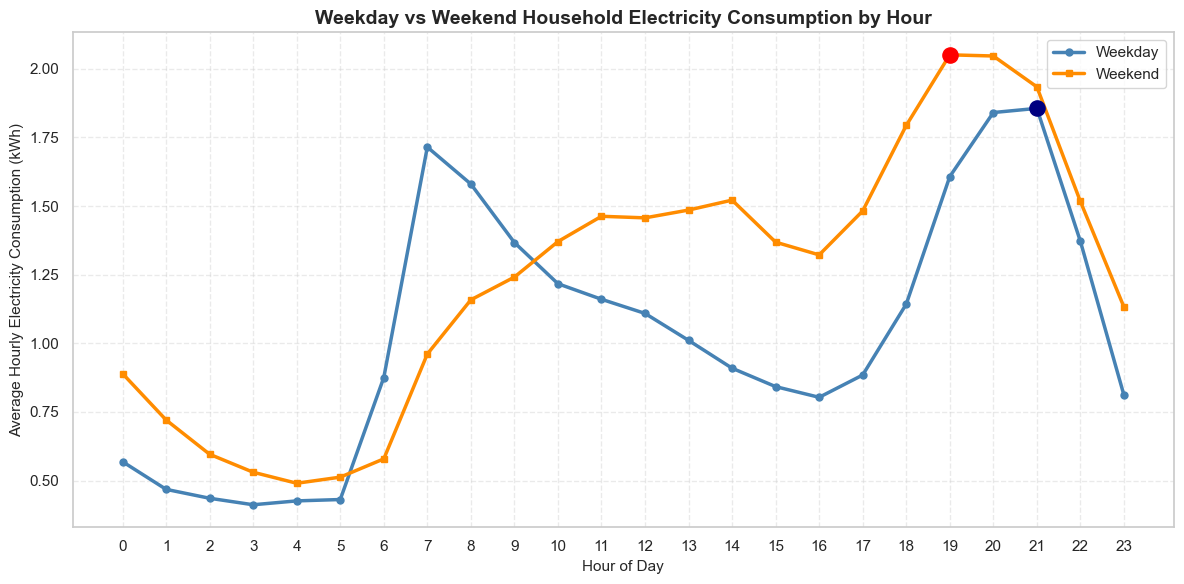

Weekday vs Weekend hourly consumption visualization completed.
Figure saved to: ../figure/weekday_weekend_hourly_profile.png


In [36]:
# Section 5.2.2 - Weekday vs Weekend Hourly Consumption

import matplotlib.pyplot as plt

hours = hourly_daytype_profile.index

fig, ax = plt.subplots(figsize=(12, 6))

# Weekday profile
ax.plot(
    hours,
    hourly_daytype_profile["Weekday"],
    color="steelblue",
    marker="o",
    linewidth=2.5,
    markersize=5,
    label="Weekday"
)

# Weekend profile
ax.plot(
    hours,
    hourly_daytype_profile["Weekend"],
    color="darkorange",
    marker="s",
    linewidth=2.5,
    markersize=5,
    label="Weekend"
)

# Identify peak hours
weekday_peak = hourly_daytype_profile["Weekday"].idxmax()
weekend_peak = hourly_daytype_profile["Weekend"].idxmax()

# Highlight weekday peak
ax.scatter(
    weekday_peak,
    hourly_daytype_profile.loc[weekday_peak, "Weekday"],
    color="navy",
    s=120,
    zorder=5
)

# Highlight weekend peak
ax.scatter(
    weekend_peak,
    hourly_daytype_profile.loc[weekend_peak, "Weekend"],
    color="red",
    s=120,
    zorder=5
)

# Chart formatting
ax.set_title(
    "Weekday vs Weekend Household Electricity Consumption by Hour",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Hour of Day", fontsize=11)
ax.set_ylabel("Average Hourly Electricity Consumption (kWh)", fontsize=11)

ax.set_xticks(range(24))
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()

# Save figure
plt.savefig(
    "../figure/weekday_weekend_hourly_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Weekday vs Weekend hourly consumption visualization completed.")
print("Figure saved to: ../figure/weekday_weekend_hourly_profile.png")